# 머신러닝 맛보기 — 실습편
**이수환** · Python 프로그래밍 특강

- 데이터: `health.csv` — **실습용 가상 데이터** 200명 (키, 몸무게, 체지방, 혈액형, 혈압, 고혈압)
- 고혈압 = 혈압 125 이상 (**실습용 가상 기준**, 실제 의학 기준과 다름)
- 사용법: 위에서부터 셀을 하나씩 실행하세요 (`Shift + Enter`). (정답 버전)

## 0. 환경 준비 (슬라이드 #3)

**처음 한 번만: 라이브러리 설치**

이 실습에는 `pandas`, `scikit-learn`, `matplotlib` 세 가지 라이브러리가 필요합니다. 아래 셀을 실행하면 설치됩니다.
- 이미 설치되어 있으면(Anaconda, Google Colab 등) `Requirement already satisfied`라고 나오고 끝납니다. 그냥 넘어가면 됩니다.
- `!pip`이 아니라 `%pip`을 쓰면, 지금 열려 있는 노트북(커널)의 파이썬에 정확히 설치됩니다.
- 설치 후 다음 셀에서 `ModuleNotFoundError`가 나면 메뉴에서 **Kernel → Restart**를 누르고 다음 셀부터 다시 실행하세요.

In [ ]:
%pip install pandas scikit-learn matplotlib

In [1]:
import platform
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

# 그래프의 한글 깨짐 방지
if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin':          # macOS
    plt.rcParams['font.family'] = 'AppleGothic'
else:                                        # Linux: 설치된 한글 폰트 찾기
    from matplotlib import font_manager
    names = {f.name for f in font_manager.fontManager.ttflist}
    korean = [n for n in ['NanumGothic', 'Noto Sans CJK KR', 'Noto Sans KR'] if n in names]
    if korean:
        plt.rcParams['font.family'] = korean[0]
    else:
        print('한글 폰트가 없어 그래프의 한글이 깨질 수 있습니다. (예: sudo apt install fonts-nanum)')
plt.rcParams['axes.unicode_minus'] = False

print('pandas', pd.__version__)
print('scikit-learn', sklearn.__version__)

pandas 3.0.5
scikit-learn 1.9.1


## Part 1. 데이터 준비
### 실습 1. 데이터 살펴보기 (슬라이드 #6 · 이론편 p.13)

In [2]:
df = pd.read_csv('health.csv')
df.head()

,키,몸무게,체지방,혈액형,혈압,고혈압
0,184,97,23.0,A,127,Y
1,179,83,20.0,O,118,N
2,173,71,15.0,A,113,N
3,188,78,25.0,B,135,Y
4,166,62,18.0,AB,109,N


In [3]:
print(df.shape)   # (샘플 수, 열 수)

(200, 6)


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   키       200 non-null    int64  
 1   몸무게     200 non-null    int64  
 2   체지방     190 non-null    float64
 3   혈액형     200 non-null    str    
 4   혈압      200 non-null    int64  
 5   고혈압     200 non-null    str    
dtypes: float64(1), int64(3), str(2)
memory usage: 9.5 KB


→ `체지방`만 Non-Null Count가 **190**입니다. 빈칸(결측치)이 10개 있다는 뜻이에요.

### 실습 2. 일단 학습시켜 보면? (슬라이드 #7)
전처리 없이 바로 모델을 학습시켜 봅니다. **에러가 나는 것이 정상입니다.** 에러 메시지의 마지막 줄을 읽어 보세요.

In [5]:
from sklearn.linear_model import LinearRegression

X = df[['키', '몸무게', '체지방']]
y = df['혈압']

model = LinearRegression()
model.fit(X, y)

ValueError: Input X contains NaN.
LinearRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

### 실습 3. 결측치 처리 (슬라이드 #8 · 이론편 p.19)

In [6]:
df.isnull().sum()

키       0
몸무게     0
체지방    10
혈액형     0
혈압      0
고혈압     0
dtype: int64

In [7]:
median = df['체지방'].median()
print('체지방 중앙값:', median)

df['체지방'] = df['체지방'].fillna(median)
df.isnull().sum()

체지방 중앙값: 18.0


키      0
몸무게    0
체지방    0
혈액형    0
혈압     0
고혈압    0
dtype: int64

In [8]:
# 다시 학습해 보기 → 이번에는 성공
X = df[['키', '몸무게', '체지방']]
model = LinearRegression()
model.fit(X, y)
print('학습 성공!')

학습 성공!


#### 데이터로 보기: 빈칸은 어떻게 채워졌을까? (슬라이드 #9)
원본을 다시 읽어서, 빈칸이 있던 행이 처리 전후에 어떻게 바뀌었는지 비교합니다.

In [9]:
raw = pd.read_csv('health.csv')   # 비교용 원본 (df는 이미 처리됨)
nan_rows = raw[raw['체지방'].isnull()].index
print('빈칸이 있던 행:', list(nan_rows))

pd.concat({'처리 전': raw.loc[nan_rows[:3], ['키', '몸무게', '체지방']],
           '처리 후': df.loc[nan_rows[:3], ['키', '몸무게', '체지방']]}, axis=1)

빈칸이 있던 행: [19, 37, 53, 93, 96, 105, 130, 136, 145, 189]


처리 전         처리 후          
      키 몸무게 체지방    키 몸무게   체지방
19  180  86 NaN  180  86  18.0
37  190  83 NaN  190  83  18.0
53  172  72 NaN  172  72  18.0

→ 10명 모두 **18.0**으로 채워졌습니다. 실제 값이 아니라 그럴듯한 추정값이라는 점을 기억하세요.

### 실습 4. 혈액형도 넣어 보면? (슬라이드 #10)
**이번에도 에러가 나는 것이 정상입니다.**

In [10]:
X = df[['키', '몸무게', '체지방', '혈액형']]
model = LinearRegression()
model.fit(X, y)

ValueError: could not convert string to float: 'A'

### 실습 5. 인코딩 (슬라이드 #11 · 이론편 p.18)
- 고혈압: 라벨 인코딩 (N → 0, Y → 1)
- 혈액형: 원-핫 인코딩 (혈액형마다 열 하나)

In [11]:
if '혈액형' in df.columns:   # 이미 인코딩했다면 건너뜀 → 이 셀을 여러 번 실행해도 안전
    df['고혈압'] = df['고혈압'].map({'N': 0, 'Y': 1})
    df = pd.get_dummies(df, columns=['혈액형'], dtype=int)
df.head()

,키,몸무게,체지방,혈압,고혈압,혈액형_A,혈액형_AB,혈액형_B,혈액형_O
0,184,97,23.0,127,1,1,0,0,0
1,179,83,20.0,118,0,0,0,0,1
2,173,71,15.0,113,0,1,0,0,0
3,188,78,25.0,135,1,0,0,1,0
4,166,62,18.0,109,0,0,1,0,0


#### 데이터로 보기: 한 사람을 따라가 보기 (슬라이드 #12)
1번 사람(혈액형 O, 고혈압 N)이 인코딩 전후에 어떻게 바뀌었는지 봅니다.

In [12]:
print('인코딩 전')
display(raw.loc[[1]])
print('인코딩 후')
display(df.loc[[1]])

인코딩 전


,키,몸무게,체지방,혈액형,혈압,고혈압
1,179,83,20.0,O,118,N


인코딩 후


,키,몸무게,체지방,혈압,고혈압,혈액형_A,혈액형_AB,혈액형_B,혈액형_O
1,179,83,20.0,118,0,0,0,0,1


→ 고혈압 N은 **0**이 되고, 혈액형 O는 `혈액형_O` 열만 **1**, 나머지 혈액형 열은 0이 됩니다.

### 전처리 완료 (슬라이드 #13)
모든 열이 숫자(int, float)가 되었는지 확인합니다.

In [13]:
df.dtypes

키           int64
몸무게         int64
체지방       float64
혈압          int64
고혈압         int64
혈액형_A       int64
혈액형_AB      int64
혈액형_B       int64
혈액형_O       int64
dtype: object

## Part 2. 회귀: 혈압 예측하기
### 실습 6. X, y 나누고 학습/테스트 분할 (슬라이드 #15 · 이론편 p.17, p.20)

In [14]:
from sklearn.model_selection import train_test_split

X = df[['키', '몸무게', '체지방']]
y = df['혈압']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

print('학습 데이터:', X_train.shape)
print('테스트 데이터:', X_test.shape)

학습 데이터: (160, 3)
테스트 데이터: (40, 3)


### 실습 7. 학습 · 예측 · 평가 (슬라이드 #16–17 · 이론편 p.9, p.30)

In [15]:
model = LinearRegression()          # ① 모델 만들기
model.fit(X_train, y_train)        # ② 학습
pred = model.predict(X_test)       # ③ 예측

result = pd.DataFrame({'실제 혈압': y_test.values, '예측 혈압': pred.round(1)})
result['오차'] = (result['실제 혈압'] - result['예측 혈압']).round(1)
result.head()

,실제 혈압,예측 혈압,오차
0,132,130.6,1.4
1,138,126.4,11.6
2,99,109.1,-10.1
3,110,119.3,-9.3
4,114,117.4,-3.4


In [16]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(y_test, pred)
print(f'평균 오차(MAE): {mae:.1f}')                          # 평균적으로 이만큼 빗나간다
print(f'결정계수(R²): {model.score(X_test, y_test):.2f}')     # 1에 가까울수록 좋다

평균 오차(MAE): 4.9
결정계수(R²): 0.67


#### 데이터로 보기: 예측은 얼마나 맞았을까? (슬라이드 #18)
점 하나가 테스트 데이터의 한 사람입니다. 점이 대각선에 가까울수록 정확한 예측입니다. 주황 원은 가장 크게 빗나간 사람입니다.

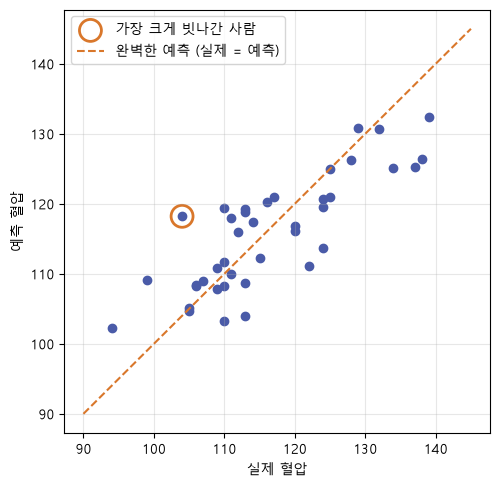

오차 5 이내: 25 / 40 명
오차 10 이내: 34 / 40 명
가장 크게 빗나간 사람: 실제 104 → 예측 118.2 (오차 14.2)


In [17]:
err = abs(y_test - pred)                    # 사람마다의 오차
worst = err.values.argmax()                 # 가장 크게 빗나간 사람의 위치

plt.figure(figsize=(5.5, 5.5))
plt.scatter(y_test, pred, color='#4A5BA8')
plt.scatter(y_test.iloc[worst], pred[worst], s=250, facecolors='none',
            edgecolors='#D9772B', linewidths=2, label='가장 크게 빗나간 사람')
plt.plot([90, 145], [90, 145], color='#D9772B', linestyle='--', label='완벽한 예측 (실제 = 예측)')
plt.xlabel('실제 혈압')
plt.ylabel('예측 혈압')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print('오차 5 이내:', (err <= 5).sum(), '/', len(y_test), '명')
print('오차 10 이내:', (err <= 10).sum(), '/', len(y_test), '명')
print(f'가장 크게 빗나간 사람: 실제 {y_test.iloc[worst]} → 예측 {pred[worst]:.1f} (오차 {err.iloc[worst]:.1f})')

### 실습 8. 모델이 찾은 규칙 (슬라이드 #19 · 이론편 p.8)
선형 회귀가 찾은 규칙: **혈압 ≈ 절편 + 계수₁×키 + 계수₂×몸무게 + 계수₃×체지방**

In [18]:
print('절편:', round(model.intercept_, 1))
pd.Series(model.coef_, index=X.columns).round(2)

절편: 72.4


키      0.03
몸무게    0.31
체지방    0.98
dtype: float64

→ 계수가 클수록 혈압에 큰 영향을 줍니다. 그렇다면 **혈액형만으로** 예측하면 어떨까요?

In [19]:
blood_cols = ['혈액형_A', '혈액형_AB', '혈액형_B', '혈액형_O']
Xb_train, Xb_test, yb_train, yb_test = train_test_split(
    df[blood_cols], df['혈압'], test_size=0.2, random_state=42)

blood_model = LinearRegression()
blood_model.fit(Xb_train, yb_train)
print(f'혈액형만 썼을 때 R²: {blood_model.score(Xb_test, yb_test):.2f}')

혈액형만 썼을 때 R²: 0.06


#### 데이터로 보기: 계수가 그렇게 나온 이유 (슬라이드 #20)

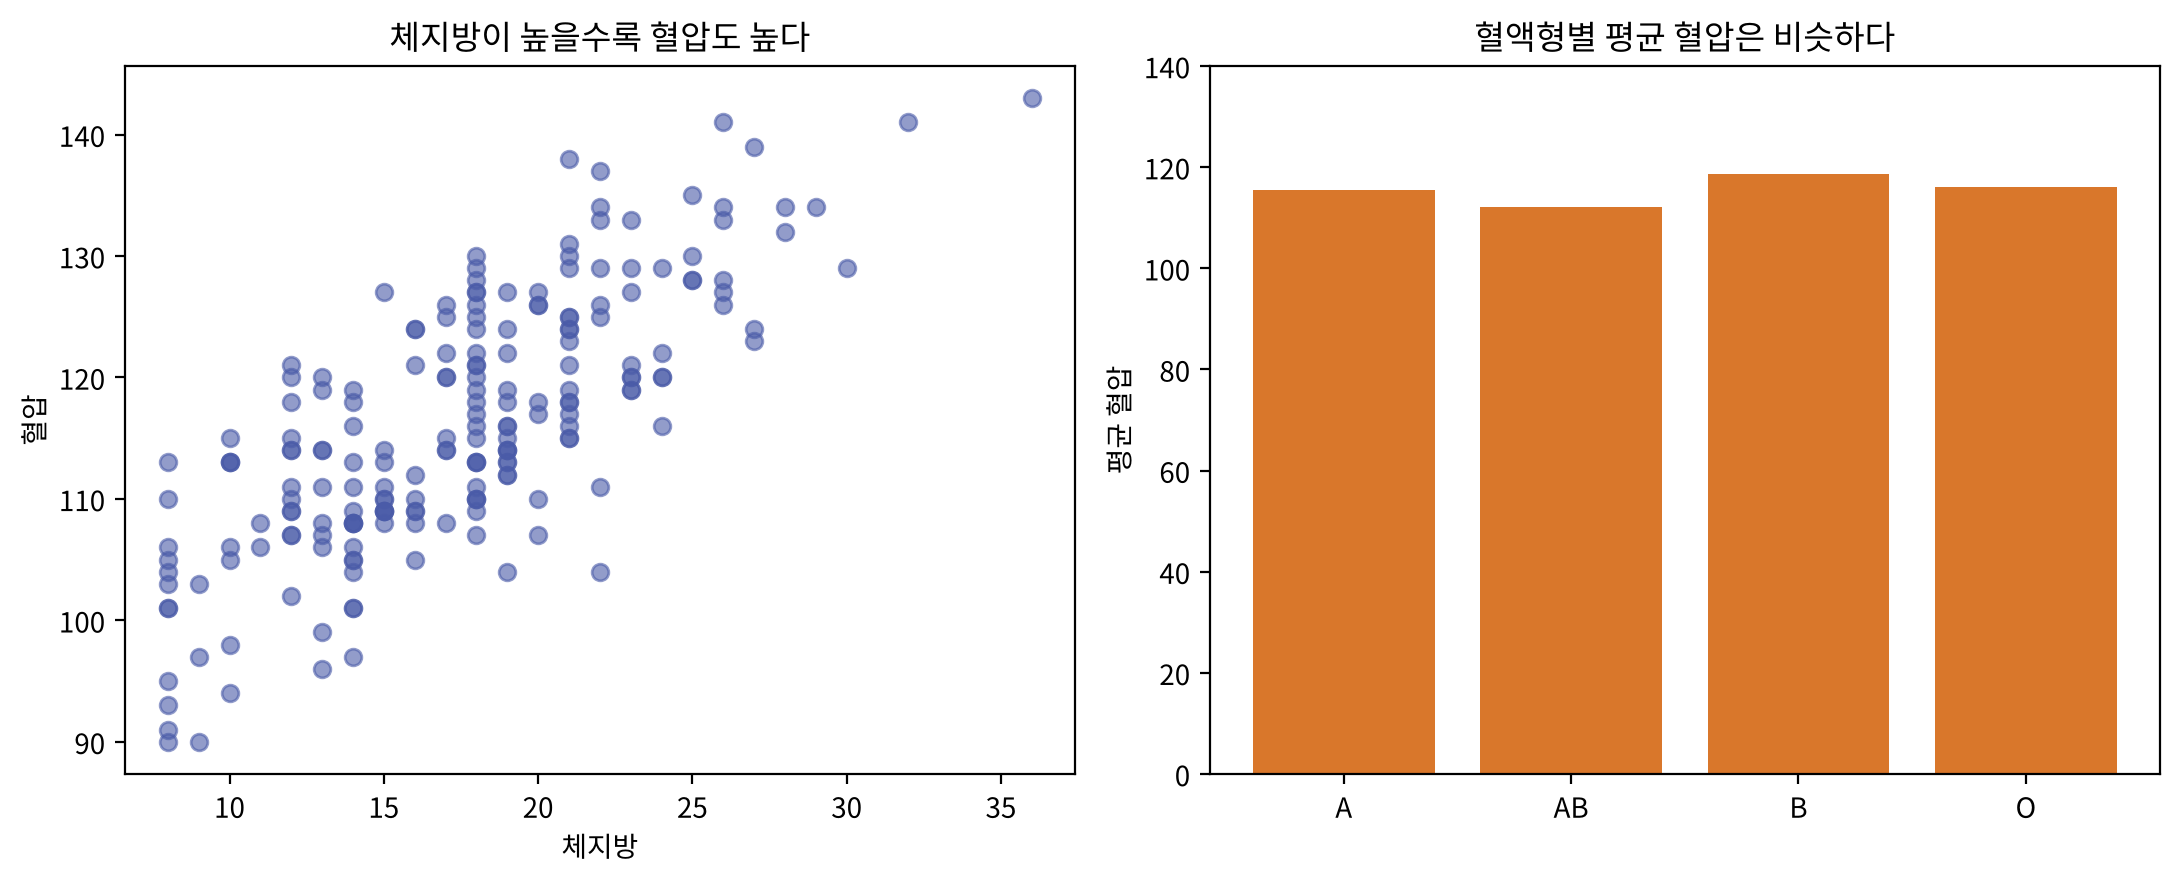

혈액형
A     115.6
AB    112.2
B     118.7
O     116.0
Name: 혈압, dtype: float64


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].scatter(df['체지방'], df['혈압'], color='#4A5BA8', alpha=0.6)
axes[0].set_xlabel('체지방')
axes[0].set_ylabel('혈압')
axes[0].set_title('체지방이 높을수록 혈압도 높다')

blood_mean = raw.groupby('혈액형')['혈압'].mean()
axes[1].bar(blood_mean.index, blood_mean.values, color='#D9772B')
axes[1].set_ylim(0, 140)
axes[1].set_ylabel('평균 혈압')
axes[1].set_title('혈액형별 평균 혈압은 비슷하다')

plt.tight_layout()
plt.show()
print(blood_mean.round(1))

### 실습 9. 내 혈압 예측하기 (슬라이드 #21)
숫자를 자신의 값으로 바꿔서 실행해 보세요.

In [21]:
me = pd.DataFrame({'키': [175], '몸무게': [70], '체지방': [18]})
print(f'예상 혈압: {model.predict(me)[0]:.1f}')

예상 혈압: 116.9


## Part 3. 분류: 고혈압 예측하기
### 실습 10. y만 바꾸면 분류 (슬라이드 #22–23 · 이론편 p.24, p.30)
X는 그대로 두고 y만 `고혈압`으로 바꿉니다.
> 생각해 보기: 왜 `혈압` 열은 X에 넣으면 안 될까요?

In [22]:
from sklearn.tree import DecisionTreeClassifier

X = df[['키', '몸무게', '체지방']]
y = df['고혈압']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

clf = DecisionTreeClassifier(random_state=42)
clf.fit(X_train, y_train)

print(f'학습 정확도: {clf.score(X_train, y_train):.3f}')
print(f'테스트 정확도: {clf.score(X_test, y_test):.3f}')

학습 정확도: 1.000
테스트 정확도: 0.775


In [23]:
# 정확도의 함정: 모두 '고혈압 아님(0)'으로 찍으면?
all_no = (y_test == 0).mean()
print(f'전부 N으로 찍었을 때 정확도: {all_no:.3f}')

전부 N으로 찍었을 때 정확도: 0.775


#### 데이터로 보기: 같은 77.5%, 다른 실수 (슬라이드 #24)
'전부 N'과 기본 트리는 정확도가 같습니다. 그런데 틀리는 방식도 같을까요?

In [24]:
pred_tree = clf.predict(X_test)

print('테스트 인원:', len(y_test), '명 / 실제 고혈압:', y_test.sum(), '명')
print()
print('[전부 N] 고혈압을 찾음: 0명 / 놓침:', y_test.sum(), '명')
print('[기본 트리] 고혈압을 찾음:', ((pred_tree == 1) & (y_test == 1)).sum(), '명',
      '/ 놓침:', ((pred_tree == 0) & (y_test == 1)).sum(), '명',
      '/ 정상인데 고혈압으로 예측:', ((pred_tree == 1) & (y_test == 0)).sum(), '명')

테스트 인원: 40 명 / 실제 고혈압: 9 명

[전부 N] 고혈압을 찾음: 0명 / 놓침: 9 명
[기본 트리] 고혈압을 찾음: 3 명 / 놓침: 6 명 / 정상인데 고혈압으로 예측: 3 명


→ 학습 정확도는 100%인데, 테스트 정확도는 **전부 N으로 찍은 것과 같습니다.** 왜 그럴까요? Part 4에서 이유를 찾아봅니다.

### 실습 11. 모델이 찾은 규칙 보기 (슬라이드 #25)
트리가 너무 깊어서 위쪽 두 단계만 그려 봅니다.

이 트리의 깊이: 14


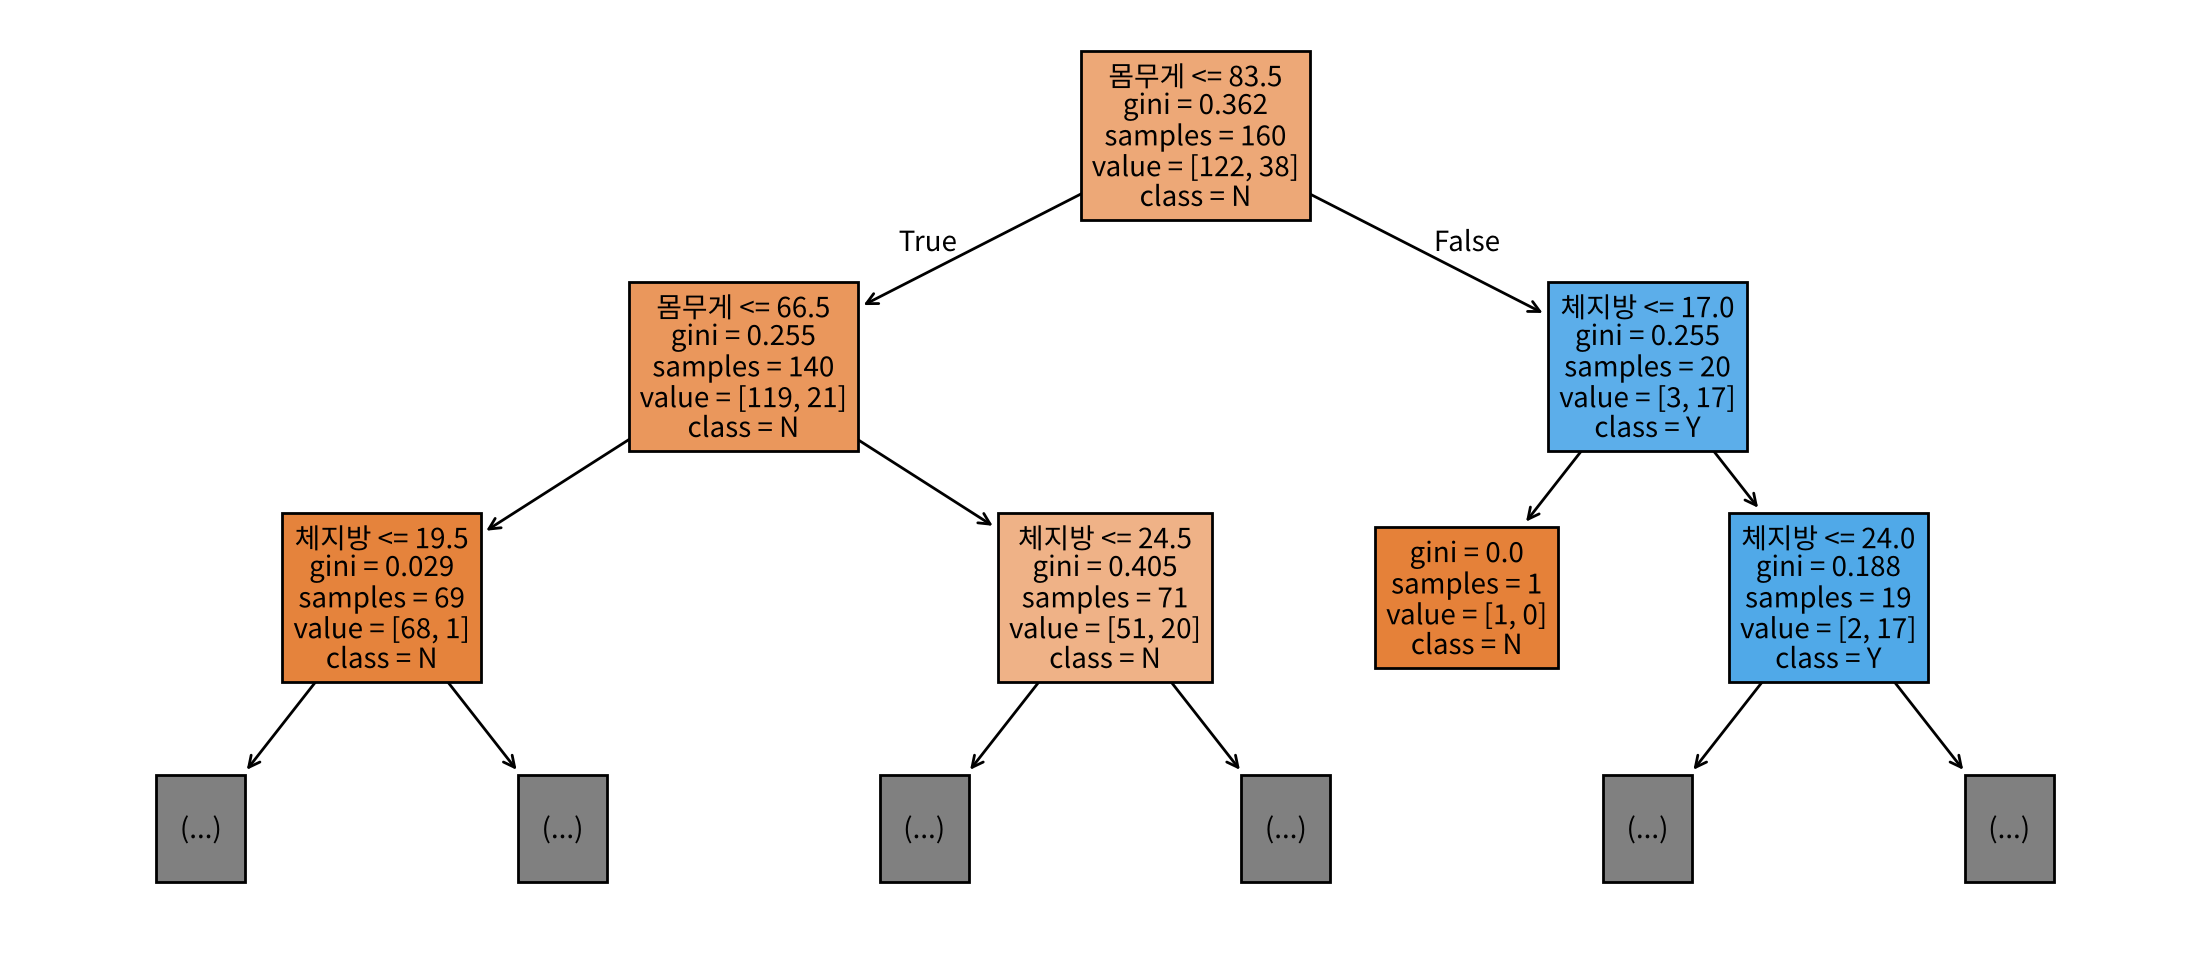

In [25]:
from sklearn.tree import plot_tree

print('이 트리의 깊이:', clf.get_depth())

plt.figure(figsize=(14, 6))
plot_tree(clf, max_depth=2, feature_names=list(X.columns),
          class_names=['N', 'Y'], filled=True, fontsize=10)
plt.show()

#### 데이터로 보기: '나'는 트리의 어디로 갈까? (슬라이드 #26)
'나'의 값을 트리에 넣고, 어떤 질문을 거쳐 답에 도착하는지 따라가 봅니다.

In [26]:
me = pd.DataFrame({'키': [175], '몸무게': [70], '체지방': [18]})

tree = clf.tree_
node = 0                                   # 맨 위(뿌리)에서 시작
while tree.children_left[node] != -1:      # 잎에 도착할 때까지
    name = X.columns[tree.feature[node]]
    value = me.iloc[0][name]
    go_left = value <= tree.threshold[node]
    print(f'{name} {value} ≤ {tree.threshold[node]:.1f} ?  →  {"예" if go_left else "아니오"}'
          f'   (이 질문까지 온 학습 데이터 {tree.n_node_samples[node]}명)')
    node = tree.children_left[node] if go_left else tree.children_right[node]

print(f'도착한 잎: 학습 데이터 {tree.n_node_samples[node]}명 → 예측', 'Y' if tree.value[node].argmax() == 1 else 'N')

몸무게 70 ≤ 83.5 ?  →  예   (이 질문까지 온 학습 데이터 160명)
몸무게 70 ≤ 66.5 ?  →  아니오   (이 질문까지 온 학습 데이터 140명)
체지방 18 ≤ 24.5 ?  →  예   (이 질문까지 온 학습 데이터 71명)
체지방 18 ≤ 16.5 ?  →  아니오   (이 질문까지 온 학습 데이터 64명)
체지방 18 ≤ 18.5 ?  →  예   (이 질문까지 온 학습 데이터 46명)
키 175 ≤ 167.5 ?  →  아니오   (이 질문까지 온 학습 데이터 15명)
키 175 ≤ 177.0 ?  →  예   (이 질문까지 온 학습 데이터 13명)
키 175 ≤ 173.5 ?  →  아니오   (이 질문까지 온 학습 데이터 9명)
도착한 잎: 학습 데이터 4명 → 예측 N


→ 질문을 8개나 거쳐 겨우 4명이 남은 곳에 도착합니다. 규칙이 너무 잘게 쪼개진 건 아닐까요? Part 4에서 확인합니다.

## Part 4. 좋은 모델 찾기
### 실습 12. 과대적합 직접 확인하기 (슬라이드 #27 · 이론편 p.29)
`max_depth`(트리의 최대 깊이)를 1부터 10까지 바꿔 가며 점수를 기록합니다.

In [27]:
records = []
for depth in range(1, 11):
    m = DecisionTreeClassifier(max_depth=depth, random_state=42)
    m.fit(X_train, y_train)
    records.append({'깊이': depth,
                    '학습 정확도': m.score(X_train, y_train),
                    '테스트 정확도': m.score(X_test, y_test)})

scores = pd.DataFrame(records)
scores

,깊이,학습 정확도,테스트 정확도
0,1,0.85000,0.900
1,2,0.85625,0.900
2,3,0.87500,0.925
3,4,0.89375,0.900
4,5,0.90000,0.900
5,6,0.92500,0.900
6,7,0.95625,0.825
7,8,0.96875,0.850
8,9,0.98125,0.775
9,10,0.98125,0.800


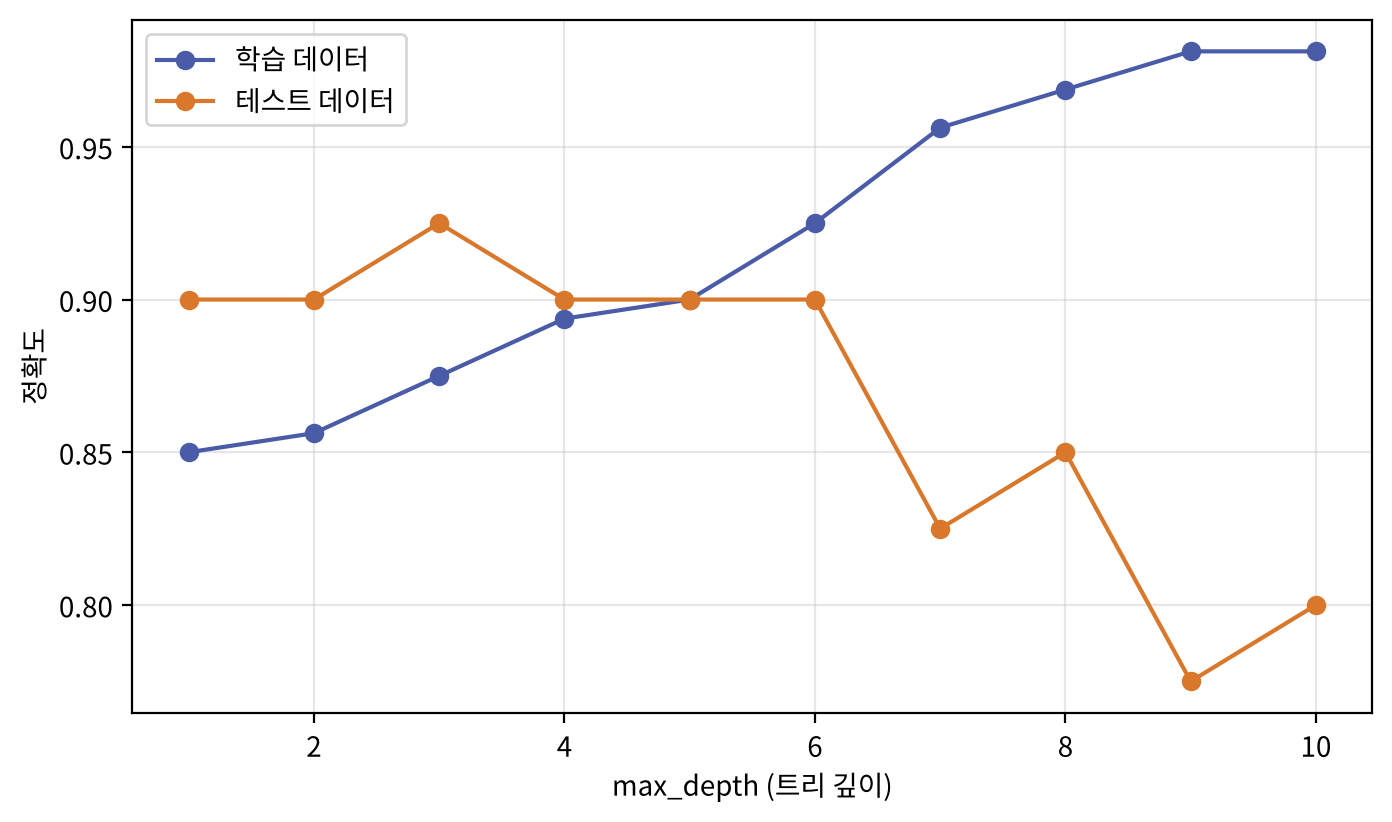

In [28]:
plt.figure(figsize=(8, 4.5))
plt.plot(scores['깊이'], scores['학습 정확도'], marker='o', color='#4A5BA8', label='학습 데이터')
plt.plot(scores['깊이'], scores['테스트 정확도'], marker='o', color='#D9772B', label='테스트 데이터')
plt.xlabel('max_depth (트리 깊이)')
plt.ylabel('정확도')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

→ 깊어질수록 학습 점수는 계속 오르지만, 테스트 점수는 어느 순간부터 떨어집니다. 이것이 **과대적합**입니다.

### 실습 13. 가장 좋은 깊이로 최종 모델 (슬라이드 #28)

In [29]:
best_depth = int(scores.loc[scores['테스트 정확도'].idxmax(), '깊이'])
print('가장 좋은 깊이:', best_depth)

final = DecisionTreeClassifier(max_depth=best_depth, random_state=42)
final.fit(X_train, y_train)
print(f'최종 테스트 정확도: {final.score(X_test, y_test):.3f}')

가장 좋은 깊이: 3
최종 테스트 정확도: 0.925


In [30]:
# '나'의 고혈압 여부 예측 (실습 9와 같은 값으로 바꿔 보세요)
me = pd.DataFrame({'키': [175], '몸무게': [70], '체지방': [18]})
print('고혈압 예측:', 'Y' if final.predict(me)[0] == 1 else 'N')

고혈압 예측: N


## 정리: 전체 흐름 한눈에 (슬라이드 #29)
불러오기 → 전처리 → X·y 나누기 → 분할 → 학습·예측·평가

In [31]:
df = pd.read_csv('health.csv')                                 # 1. 불러오기
df['체지방'] = df['체지방'].fillna(df['체지방'].median())         # 2. 전처리

X = df[['키', '몸무게', '체지방']]                                 # 3. X, y 나누기
y = df['혈압']

X_train, X_test, y_train, y_test = train_test_split(              # 4. 분할
    X, y, test_size=0.2, random_state=42)

model = LinearRegression()                                        # 5. 학습·예측·평가
model.fit(X_train, y_train)
print(f'R²: {model.score(X_test, y_test):.2f}')

R²: 0.67


### 더 해보기
- 모델 바꿔 보기: `from sklearn.ensemble import RandomForestClassifier`, `from sklearn.neighbors import KNeighborsClassifier`
- 실제 데이터에 도전: Kaggle **Titanic** 생존자 예측
- scikit-learn 공식 튜토리얼: https://scikit-learn.org/stable/tutorial/